## Chatbot with TOOLS


In [1]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tool.invoke("Explain about langchain_tavily")

{'query': 'Explain about langchain_tavily',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.npmjs.com/package/@langchain/tavily',
   'title': '@langchain/tavily - npm',
   'content': 'NPM - Version\n\nThis package provides integrations for the Tavily search engine within LangChain.js. Tavily is a search engine built specifically for AI agents (LLMs), delivering real-time, accurate, and factual results at speed.\n\nThis package exposes four tools:\n\n`TavilySearch`\n`TavilyExtract`\n`TavilyCrawl`\n`TavilyMap`\n`TavilyResearch`\n`TavilyGetResearch`\n`request_id`\n\n## Installation\n\n## Setup',
   'score': 0.78334314,
   'raw_content': None,
   'id': 'e731a3-00'},
  {'url': 'https://patotricks15.medium.com/building-a-smart-search-agent-with-langchain-and-tavily-search-6838076e35f1',
   'title': 'Medium',
   'content': '## Introduction\n\nIn this tutorial, we will build a smart search agent using LangChain, a framework designed to facilitate

In [3]:
# Custom function
def multiple(a:int, b:int) -> int:
    """
    Multiple a and b
    Args:
        a (int): first number
        b (int): second number
    Returns:
        int: output int
    """
    return a * b

In [4]:
tools = [tool, multiple]

In [5]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b")

In [6]:
llm_with_tools = llm.bind_tools(tools)

In [7]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x115bd9940>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x115bda660>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted resu

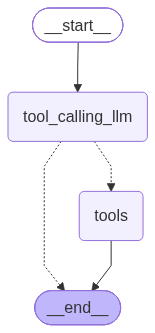

In [8]:
# StateGraph
from typing import Annotated
from typing_extensions import TypedDict
from IPython.display import Image, display
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# State
class State(TypedDict):
    messages: Annotated[list,add_messages]

# Node definitions
def tool_calling_llm(state:State):
    response = llm_with_tools.invoke(state["messages"])
    return { "messages" : [response]}

# Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # if the latest message is a tool call, then go to the tool node
    # if the latest message is not a tool call, then go to the END node
    tools_condition
)
builder.add_edge("tools",END)

# Compile
graph = builder.compile()

# Visualize
display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
response = graph.invoke({
    "messages" : ["what is the recent AI news?"]
})

In [10]:
response["messages"][-1]

ToolMessage(content='{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.marketingprofs.com/opinions/2026/56118/ai-update-october-09-2026-ai-news-and-views-from-the-past-week", "title": "Artificial Intelligence - AI Update, October 09, 2026: AI News and Views From the Past Week", "content": "OpenAI introduces visual ChatGPT ads and expands advertising measurement capabilities. OpenAI is introducing a visual advertising format within ChatGPT\'s image-generation experience, initially testing it with Free and Go users in the US later this month. The company is also expanding conversion tracking, attribution, and incrementality measurement through partnerships with Hightouch, LiveRamp, Tealium, and numerous analytics providers. Early partner findings include a 15.3% lower attributed acquisition cost for WeightWatchers compared with its paid-search benchmark and substantial new-customer activity for other adver

In [11]:
response = graph.invoke({
    "messages" : ["What is the multiple of 5 and 6?"]
})

In [12]:
response

{'messages': [HumanMessage(content='What is the multiple of 5 and 6?', additional_kwargs={}, response_metadata={}, id='0be2aac5-9f59-44b1-b1b7-97275eec95f3'),
  AIMessage(content='The product (multiple) of 5 and 6 is **30**.', additional_kwargs={'reasoning_content': 'User asks: "What is the multiple of 5 and 6?" Likely they mean product? The multiple of two numbers could be product. So 5*6 =30. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 376, 'total_tokens': 443, 'completion_time': 0.138181392, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.005741095, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.3070441, 'total_time': 0.143922487}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_87b3c396db', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a124c7-4c38-76d2-a8a5-7354fe60f48b-0', tool_calls=[], invalid_tool_calls=[

In [30]:
response = graph.invoke({
    "messages" : ["What is the recent tweet from @elonmusk? about ambani and then multiple of 5 and 6"]
})
response

{'messages': [HumanMessage(content='What is the recent tweet from @elonmusk? about ambani and then multiple of 5 and 6', additional_kwargs={}, response_metadata={}, id='dbd02926-1902-41d9-8f5f-65b3339b9e4b'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to answer: "What is the recent tweet from @elonmusk? about ambani and then multiple of 5 and 6"\n\nInterpretation: The user asks for two things: (1) the recent tweet from Elon Musk about Ambani; (2) the multiple of 5 and 6 (i.e., compute 5*6 = 30). We need to provide the tweet and the product.\n\nWe need to fetch recent tweet. Use search to find recent tweet. Use functions.tavily_search with query "Elon Musk Ambani tweet". Probably need recent. Use time_range maybe "day" or "week". Let\'s search.', 'tool_calls': [{'id': 'fc_c0162769-e111-4744-bfb3-77c8b48f01ca', 'function': {'arguments': '{"query":"Elon Musk tweet Ambani","search_depth":"advanced","time_range":"week"}', 'name': 'tavily_search'}, 'type': 'func

In [31]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent tweet from @elonmusk? about ambani and then multiple of 5 and 6
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_c0162769-e111-4744-bfb3-77c8b48f01ca)
 Call ID: fc_c0162769-e111-4744-bfb3-77c8b48f01ca
  Args:
    query: Elon Musk tweet Ambani
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "Elon Musk tweet Ambani", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.livemint.com/news/india/dear-prime-minister-ambani-elon-musk-reignites-debate-over-starlinks-pending-india-licence-11791568466890.html", "title": "Elon Musk's latest tweet: 'Dear PM Ambani, Please accept my humble apologies' - Read full text | Today News", "content": "mint\n\nView Market Dashboard\n\n# Elon Musk'